## Задача 6. BFS on GPU

**1. Используя `OpenCL` или `CUDA` реализовать алгоритм обхода в ширину ориентированного графа на GPU. Реализация не обязательно должна использовать операции линейной алгебры, можно взять классический алгоритм BFS.**

In [1]:
import os
import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy.io import mmread
from collections import deque
import time
import networkx as nx
import pyopencl as cl
import matplotlib.pyplot as plt
from warnings import filterwarnings

filterwarnings('ignore')
plt.style.use('classic')

In [2]:
# OPENCL
ctx = cl.create_some_context()
queue = cl.CommandQueue(ctx)

kernel_code = """
__kernel void bfs_step(
    __global const int* indptr,
    __global const int* indices,
    __global int* levels,
    const int current_level,
    __global int* changed
) {
    int u = get_global_id(0);
    if (levels[u] == current_level) {
        int start = indptr[u];
        int end = indptr[u + 1];
        for (int i = start; i < end; i++) {
            int v = indices[i];
            if (levels[v] == -1) {
                levels[v] = current_level + 1;
                *changed = 1;
            }
        }
    }
}
"""
prg = cl.Program(ctx, kernel_code).build()


def cpu_bfs(csr_matrix, source=0):
    """BFS на CPU с использованием очереди."""
    n_vertices = csr_matrix.shape[0]
    levels = np.full(n_vertices, -1, dtype=np.int32)
    levels[source] = 0
    
    queue_nodes = deque([source])
    indptr = csr_matrix.indptr
    indices = csr_matrix.indices
    
    while queue_nodes:
        u = queue_nodes.popleft()
        curr_level = levels[u]
        
        for v in indices[indptr[u]:indptr[u+1]]:
            if levels[v] == -1:
                levels[v] = curr_level + 1
                queue_nodes.append(v)
                
    return levels


def gpu_bfs(csr_matrix, source=0):
    """BFS на GPU через PyOpenCL."""
    n_vertices = csr_matrix.shape[0]
    indptr = csr_matrix.indptr.astype(np.int32)
    indices = csr_matrix.indices.astype(np.int32)
    
    levels = np.full(n_vertices, -1, dtype=np.int32)
    levels[source] = 0
    
    # создание буферов на GPU
    mf = cl.mem_flags
    indptr_g = cl.Buffer(ctx, mf.READ_ONLY | mf.COPY_HOST_PTR, hostbuf=indptr)
    indices_g = cl.Buffer(ctx, mf.READ_ONLY | mf.COPY_HOST_PTR, hostbuf=indices)
    levels_g = cl.Buffer(ctx, mf.READ_WRITE | mf.COPY_HOST_PTR, hostbuf=levels)
    
    changed = np.array([0], dtype=np.int32)
    changed_g = cl.Buffer(ctx, mf.READ_WRITE, size=changed.nbytes)
    
    current_level = 0
    
    while True:

        changed[0] = 0
        cl.enqueue_copy(queue, changed_g, changed)
        
        # запуск ядра
        prg.bfs_step(queue, (n_vertices,), None, 
                     indptr_g, indices_g, levels_g, 
                     np.int32(current_level), changed_g)
        
        cl.enqueue_copy(queue, changed, changed_g)
        
        if changed[0] == 0:
            break
            
        current_level += 1

    cl.enqueue_copy(queue, levels, levels_g)
    return levels

**2. Провести экспериментальное исследование полученной реализации и сравнить её с реализацией этого же алгоритма на CPU. Графы брать разного размера, например с сайта SuiteSparse Matrix Collection. На некоторых графах добиться прироста производительности при использовании GPU.**

In [3]:
files = os.listdir('./data')
files

['lshp3025.mtx',
 'M6.mtx',
 'relat9.mtx',
 'road_usa.mtx',
 'wb-edu.mtx',
 'web-Stanford.mtx']

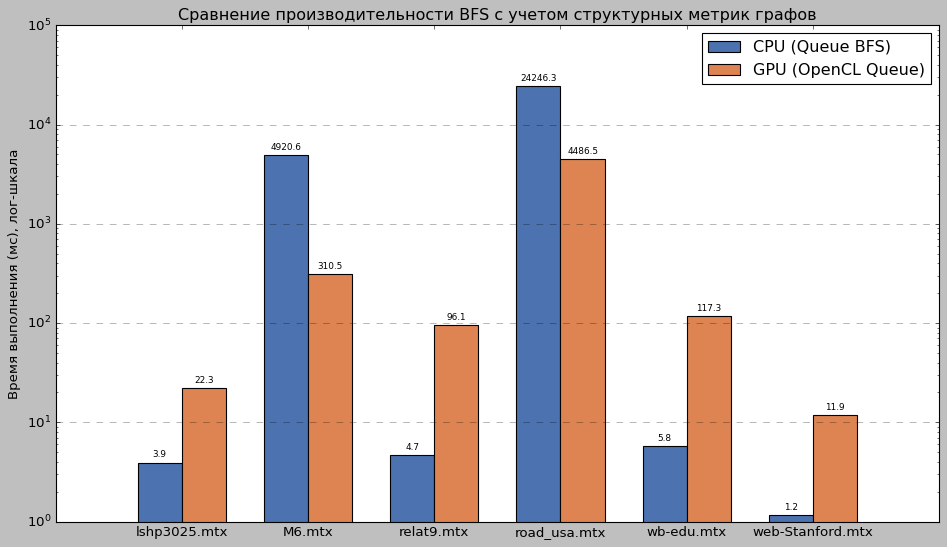

In [ ]:
results = {}

for file in files:
    file_path = os.path.join('./data', file)
    if not os.path.exists(file_path):
        continue

    matrix = mmread(file_path)
    csr_graph = matrix.tocsr()
    
    n_v = csr_graph.shape[0]
    n_e = csr_graph.nnz
    
    degrees = np.diff(csr_graph.indptr)
    avg_deg = np.mean(degrees) if n_v > 0 else 0
    max_deg = np.max(degrees) if n_v > 0 else 0
    
    density = n_e / (n_v ** 2) if n_v > 0 else 0
    
    source_vertex = 0
    
    # CPU
    t0 = time.perf_counter()
    cpu_res = cpu_bfs(csr_graph, source_vertex)
    t1 = time.perf_counter()
    cpu_time = (t1 - t0) * 1000 
    
    # GPU
    t0 = time.perf_counter()
    gpu_res = gpu_bfs(csr_graph, source_vertex)
    t1 = time.perf_counter()
    gpu_time = (t1 - t0) * 1000 
    
    speedup = cpu_time / gpu_time if gpu_time > 0 else 0
    
    results[file] = {
        'Vertices': n_v, 'Edges': n_e, 'Density': density,
        'Avg Degree': avg_deg, 'Max Degree': max_deg,
        'cpu': cpu_time, 'gpu': gpu_time, 'Speedup': speedup
    }


df = pd.DataFrame.from_dict(results, orient='index')
df.index.name = 'Graph File'
df.reset_index(inplace=True)


# визуализация
labels = list(results.keys())
cpu_times = [results[k]['cpu'] for k in labels]
gpu_times = [results[k]['gpu'] for k in labels]

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 7))
rects1 = ax.bar(x - width/2, cpu_times, width, label='CPU (Queue BFS)', color='#4C72B0')
rects2 = ax.bar(x + width/2, gpu_times, width, label='GPU (OpenCL Queue)', color='#DD8452')

ax.set_ylabel('Время выполнения (мс), лог-шкала')
ax.set_title('Сравнение производительности BFS')
ax.set_xticks(x)
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.set_yscale('log')
ax.set_xticklabels(labels)

for rect in rects1 + rects2:
    height = rect.get_height()
    ax.annotate(f'{height:.1f}',
                xy=(rect.get_x() + rect.get_width() / 2, height),
                xytext=(0, 3),
                textcoords="offset points",
                ha='center', va='bottom', fontsize=8)

fig.tight_layout()
plt.savefig('bfs_benchmark_results.png', dpi=300)
plt.show()

In [5]:
df

,Graph File,Vertices,Edges,Density,Avg Degree,Max Degree,cpu,gpu,Speedup
0,lshp3025.mtx,3025,20833,2.276675e-03,6.886942,7,3.9282,22.3289,0.175924
1,M6.mtx,3501776,21003872,1.712863e-06,5.998063,10,4920.6026,310.4655,15.849112
2,relat9.mtx,12360060,38955420,2.549921e-07,3.151718,4,4.7207,96.1258,0.049110
3,road_usa.mtx,23947347,57708624,1.006296e-07,2.409813,9,24246.2642,4486.5114,5.404258
4,wb-edu.mtx,9845725,57156537,5.896177e-07,5.805214,3841,5.8047,117.2589,0.049503
5,web-Stanford.mtx,281903,2312497,2.909925e-05,8.203166,255,1.1546,11.9100,0.096944


Производительность GPU нестабильна и сильно зависит от топологии графа. Для небольших графов видно, что реализация на GPU уступает по времени на CPU, так как существенное время занимает пересылка данных в память GPU.